This script contains python code for solving the following linear optimization problem.
\begin{equation}
\begin{aligned}
    &\underset{\bf{x}, \bf{y}, \bf{z} \in \Re^{52}}{\textnormal{maximize}} && \sum_{t=1}^{52} \left(-c_t x_t - h y_t + p_t z_t \right) \\
    &\textnormal{subject to}&& y_{t} = y_{t-1} + x_t - z_t && \forall t \in \{1,\ldots,51\} \\
    &&& 0 \le y_t \le w && \forall t \in \{1,\ldots,52\} \\
    &&& 0 \le x_t \le q_t && \forall t \in \{1,\ldots,52\}\\
    &&& 0 \le z_t \le d_t && \forall t \in \{1,\ldots,52\}\\
    &&& z_t \le y_{t-1} + x_t && \forall t \in \{1,\ldots,52\}\\
    &&& y_0 = 0
\end{aligned}
\end{equation}

Load in the libraries

In [1]:
import gurobipy as gp
from gurobipy import GRB
import math
import matplotlib.pyplot as plt
import random

## Generate the problem data

In [2]:
# Time horizon in weeks
T = 52

Create the demand, and plot the demand and the maximum ordering quantities:

Text(0, 0.5, 'Quantity')

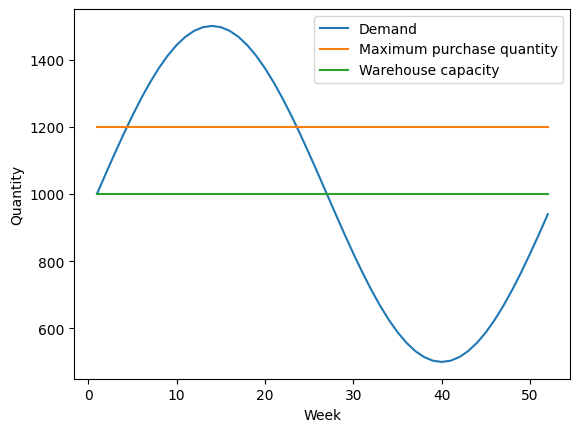

In [3]:
# Demand in week t: d_t
d = {t: 1000*(1 + 0.5*math.sin(2*math.pi*(t-1)/T)) for t in range(1,T+1)}

# Max number of backpacks you can order in week t: q_t
q = {t: 1200 for t in range(1,T+1)}  

# Warehouse capacity: w
w = 1000  # Maximum inventory allowed at the end of each week

# Create the plot
plt.plot(range(1,T+1), [d[t] for t in range(1,T+1)], label="Demand")
plt.plot(range(1,T+1), [q[t] for t in range(1,T+1)], label="Maximum purchase quantity")
plt.plot(range(1,T+1), [w for _ in range(T)], label="Warehouse capacity")
plt.legend()
plt.xlabel("Week")
plt.ylabel("Quantity")

In [4]:
# Holding cost per backpack in inventory per week
h = 0.1

Text(0.5, 1.0, 'Price and cost')

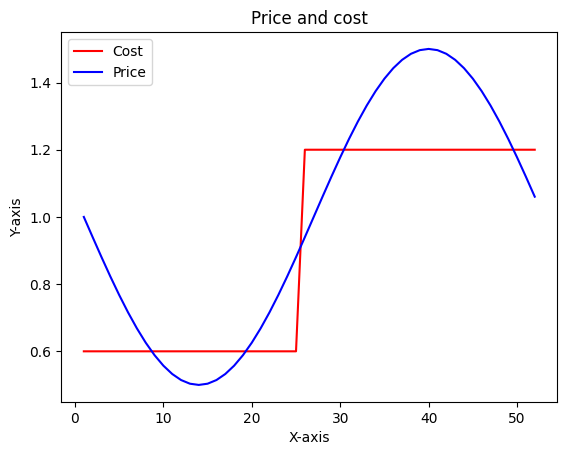

In [5]:
# Selling price in week t: p_t
p = {t: 1 - 0.5*math.sin(2*math.pi*(t-1)/T) for t in range(1,T+1)}

# Cost to order (purchase) each backpack in week t: c_t
c = {}
for t in range(1,T+1):
    if t <= 25:
        c[t] = 0.6
    else:
        c[t] = 1.2

# Plot the price and cost
plt.plot(range(1,T+1), [c[t] for t in range(1,T+1)], label="Cost", color="red")
plt.plot(range(1,T+1), [p[t] for t in range(1,T+1)], label="Price", color="blue")
plt.legend()
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Price and cost")

In [6]:
# Create model
model = gp.Model("Inventory Optimization")

# Decision variables (note that it includes the upper bounds directly)
# IMPORTANT: the decision variables for x and z are not indexed starting at 0 
x = model.addVars(range(1,T+1), lb=0, name="x")  # Order quantity
y = model.addVars(range(0,T+1), lb=0, name="y")  # Inventory level
z = model.addVars(range(1,T+1), lb=0, name="z")  # Sales quantity

# Objective function: Maximize profit
# Note: Gurobi typically runs faster whne using `quicksum` versus `sum`
model.setObjective(
    gp.quicksum(-c[t] * x[t] - h * y[t] + p[t] * z[t] for t in range(1,T+1)), 
    GRB.MAXIMIZE
)

# Constraints

# Inventory balance constraint
for t in range(1, T+1):
    model.addConstr(y[t] == y[t-1] + x[t] - z[t])

# Warehouse constraint
for t in range(1, T+1):
    model.addConstr(y[t] <= w)

# Ordering constraint
for t in range(1, T+1):
    model.addConstr(x[t] <= q[t])

# Demand constraint
for t in range(1, T+1):
    model.addConstr(z[t] <= d[t])
    
# Sales constraint
for t in range(1,T+1):
    model.addConstr(z[t] <= y[t-1] + x[t])

# Initial inventory constraint
model.addConstr(y[0] == 0, "initial_inventory")

# Solve model
model.optimize()

Set parameter Username
Set parameter LicenseID to value 2868056
Academic license - for non-commercial use only - expires 2027-09-25
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 155H, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 22 logical processors, using up to 22 threads

Optimize a model with 261 rows, 157 columns and 521 nonzeros (Max)
Model fingerprint: 0x71a48438
Model has 156 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e-01, 2e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [5e+02, 2e+03]

Presolve removed 157 rows and 1 columns
Presolve time: 0.03s
Presolved: 104 rows, 156 columns, 362 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    3.9800000e+04   7.408248e+03   0.000000e+00      0s
      88    4.9536145e+03   0.000000e+00   0.000000e+00      0s

Solved in 88 iterations a

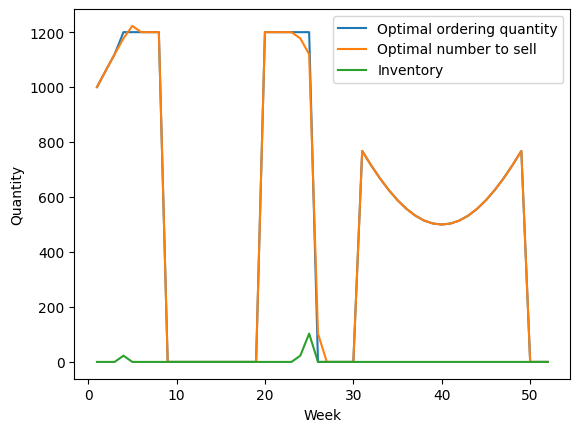

In [7]:
# Plot the results
if model.status == GRB.OPTIMAL:
    plt.plot(range(1,T+1), [x[t].X for t in range(1,T+1)], label="Optimal ordering quantity")
    plt.plot(range(1,T+1), [z[t].X for t in range(1,T+1)], label="Optimal number to sell")
    plt.plot(range(1,T+1), [y[t].X for t in range(1,T+1)], label="Inventory")
    plt.legend()
    plt.xlabel("Week")
    plt.ylabel("Quantity")
else:
    print("No optimal solution found")